In [ ]:
# ==========================================
!pip install pydicom
# STEP 1: INSTALL & IMPORT LIBRARIES (Day 1)
# ==========================================
# Run this if pydicom isn't installed: !pip install pydicom
import pydicom
import numpy as np
import matplotlib.pyplot as plt
from pydicom.data import get_testdata_files

# ==========================================
# STEP 2: LOAD DATA & METADATA (Day 1)
# ==========================================
# Get a sample CT slice from the pydicom library
filename = get_testdata_files("CT_small.dcm")[0]
ds = pydicom.dcmread(filename)

# Extract raw pixel grid
image_array = ds.pixel_array

# ==========================================
# STEP 3: PHYSICS CALIBRATION (Day 2)
# ==========================================
# Convert raw values to Hounsfield Units (HU)
# Formula: HU = (Raw * Slope) + Intercept
hu_image = image_array * ds.RescaleSlope + ds.RescaleIntercept


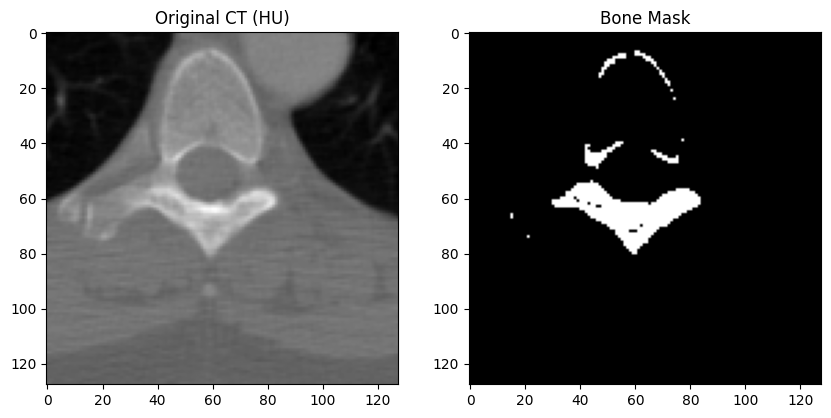

In [ ]:
# 1. Define the bone threshold
bone_threshold = 400

# 2. Create the mask
# This creates a 'True' for bone pixels and 'False' for everything else
bone_mask = hu_image > bone_threshold

# 3. Visualize the result
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(hu_image, cmap='gray')
plt.title("Original CT (HU)")

plt.subplot(1, 2, 2)
plt.imshow(bone_mask, cmap='gray')
plt.title("Bone Mask")

plt.show()

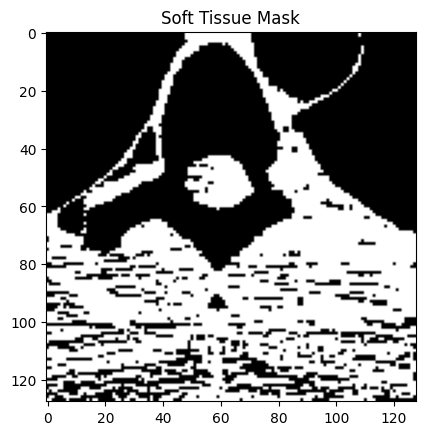

In [ ]:
# Select only 'Soft Tissue' (Between -100 and 100)
# We use & (and) to combine two conditions
soft_tissue_mask = (hu_image > -100) & (hu_image < 60)

plt.imshow(soft_tissue_mask, cmap='gray')
plt.title("Soft Tissue Mask")
plt.show()

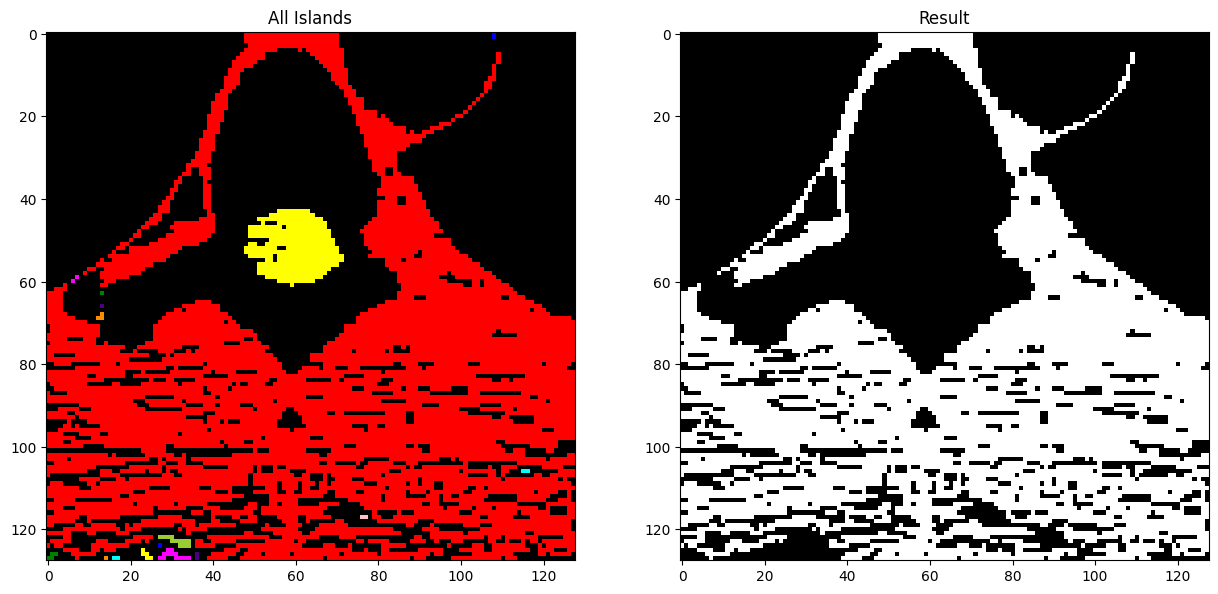

In [ ]:
from skimage import measure

# This creates a new image where instead of 0s and 1s,
# you have 0s (background), 1s (Island A), 2s (Island B), etc.
labels = measure.label(soft_tissue_mask)
from skimage import measure, color
# 2. Convert labels to a color image (Every ID gets a unique color)
# bg_label=0 ensures the background stays black
colored_islands = color.label2rgb(labels, bg_label=0)

# 3. Create the "Largest Only" version
props = measure.regionprops(labels)
largest_id = props[np.argmax([p.area for p in props])].label
largest_only_mask = (labels == largest_id)

# Create 1 row and 2 columns immediately
fig, ax = plt.subplots(1, 2, figsize=(15, 7))

# Use ax[0] for the left side
ax[0].imshow(colored_islands)
ax[0].set_title("All Islands")

# Use ax[1] for the right side
ax[1].imshow(largest_only_mask, cmap='gray')
ax[1].set_title("Result")

plt.show()



